# 03. LightGBM 기준 모델과 Validation 평가

Spark로 저장한 특징을 재사용한다. 단일 머신 LightGBM 학습을 위해 선택한 컬럼만 Pandas로 읽는다. Test는 최종 평가를 위해 보존한다. Validation에서 조기 종료와 F1 최대 임계값을 선택하므로 여기서 보고하는 성능은 선택용 성능으로 해석한다.

In [1]:
import json
from datetime import datetime, timezone
from pathlib import Path
from uuid import uuid4

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.metrics import (
    auc,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
manifests = sorted((ROOT / "artifacts/features/paysim_temporal").glob("*/manifest.json"))
verified = [(p, json.loads(p.read_text())) for p in manifests]
verified = [(p, m) for p, m in verified if m.get("verified") is True]
assert verified, "검증된 특징 산출물을 먼저 생성한다."
source_path, source = verified[-1]
features = source["model_features"]
assert not set(features) & {
    "isFraud",
    "isFlaggedFraud",
    "newbalanceOrig",
    "newbalanceDest",
    "nameOrig",
    "nameDest",
}
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid4().hex[:8]
report = ROOT / "artifacts/reports" / run_id
model_dir = ROOT / "artifacts/models" / run_id
report.mkdir(parents=True)
model_dir.mkdir(parents=True)
print("Source:", source["run_id"], "Run:", run_id)

Source: 20261117T090124Z-c769f595 Run: 20261119T072526Z-09107167


## 입력 준비

Train에서만 거래 유형 목록을 결정한다. Validation의 미등록 유형은 결측 범주로 처리한다. 원본 manifest와 행 수·정답 건수·시간 경계를 대조한다.

In [2]:
data_path = ROOT / source["parquet_path"]
frames = {}
for split in ["train", "validation"]:
    frame = pd.read_parquet(data_path / f"split={split}", columns=features + ["isFraud"])
    expected = next(s for s in source["splits"] if s["split"] == split)
    assert len(frame) == expected["rows"]
    assert int(frame.isFraud.sum()) == expected["fraud"]
    assert frame.isFraud.nunique() == 2
    frames[split] = frame
train, validation = frames["train"], frames["validation"]
assert train.step.max() < validation.step.min()
categories = sorted(train["type"].unique().tolist())
for frame in frames.values():
    frame["type"] = pd.Categorical(frame["type"], categories=categories)
X_train, y_train = train[features], train["isFraud"]
X_valid, y_valid = validation[features], validation["isFraud"]
display(
    pd.DataFrame(
        [{"split": s, "rows": len(f), "fraud": int(f.isFraud.sum())} for s, f in frames.items()]
    )
)

,split,rows,fraud
0,train,3820599,3193
1,validation,1248498,762


## 기준 모델 학습

고정 seed와 파라미터로 재현 가능한 기준 모델을 학습한다. Validation average precision으로 조기 종료한다. 클래스 가중치 튜닝은 후속 비교 실험에서 수행한다.

In [3]:
model = lgb.LGBMClassifier(
    objective="binary",
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=100,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=4,
    verbosity=-1,
    deterministic=True,
    force_col_wise=True,
    metric="average_precision",
)
model.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    eval_metric="average_precision",
    callbacks=[lgb.early_stopping(40, first_metric_only=False), lgb.log_evaluation(50)],
)
scores = model.predict_proba(X_valid)[:, 1]
assert np.isfinite(scores).all()
print("Best iteration:", model.best_iteration_)

/Users/yueun/Desktop/FDS-AI-Agent/.venv/lib/python3.11/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 40 rounds


[50]	valid_0's average_precision: 0.692304


[100]	valid_0's average_precision: 0.712044


[150]	valid_0's average_precision: 0.723038


[200]	valid_0's average_precision: 0.731528


... (3 outputs left out)

[400]	valid_0's average_precision: 0.754827


[450]	valid_0's average_precision: 0.757316


Early stopping, best iteration is:
[444]	valid_0's average_precision: 0.758877


Best iteration: 444


## 임계값 선택과 지표

Validation F1이 최대가 되는 임계값을 선택한다. 동률이면 높은 임계값을 선택한다. PR-AUC는 사다리꼴 적분으로 계산하고 Average Precision도 별도로 기록한다. 기본 임계값 0.5와 선택 임계값을 비교한다.

,policy,threshold,precision,recall,f1,pr_auc,average_precision,tn,fp,fn,tp
0,default,0.500000,0.854167,0.591864,0.699225,0.758815,0.758877,1247659,77,311,451
1,validation_f1,0.290304,0.794793,0.681102,0.733569,0.758815,0.758877,1247602,134,243,519


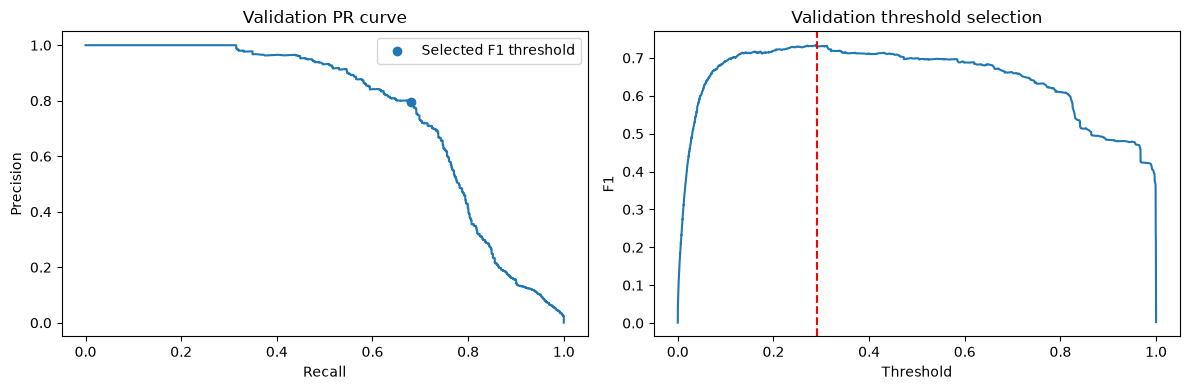

In [4]:
precision, recall, thresholds = precision_recall_curve(y_valid, scores)
f1 = np.divide(
    2 * precision[:-1] * recall[:-1],
    precision[:-1] + recall[:-1],
    out=np.zeros_like(thresholds),
    where=(precision[:-1] + recall[:-1]) > 0,
)
best = np.flatnonzero(f1 == f1.max())[-1]
threshold = float(thresholds[best])
rows = []
for name, cutoff in [("default", 0.5), ("validation_f1", threshold)]:
    predicted = scores >= cutoff
    tn, fp, fn, tp = confusion_matrix(y_valid, predicted, labels=[0, 1]).ravel()
    rows.append(
        dict(
            policy=name,
            threshold=cutoff,
            precision=float(precision_score(y_valid, predicted, zero_division=0)),
            recall=float(recall_score(y_valid, predicted, zero_division=0)),
            f1=float(f1_score(y_valid, predicted, zero_division=0)),
            pr_auc=float(auc(recall, precision)),
            average_precision=float(average_precision_score(y_valid, scores)),
            tn=int(tn),
            fp=int(fp),
            fn=int(fn),
            tp=int(tp),
        )
    )
metrics = pd.DataFrame(rows)
display(metrics)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(recall, precision)
axes[0].scatter(recall[best], precision[best], label="Selected F1 threshold")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Validation PR curve")
axes[0].legend()
axes[1].plot(thresholds, f1)
axes[1].axvline(threshold, color="red", linestyle="--")
axes[1].set(xlabel="Threshold", ylabel="F1", title="Validation threshold selection")
fig.tight_layout()
fig.savefig(report / "validation_curves.png", dpi=150)
plt.show()

## 산출물 저장

모델과 입력 컬럼 순서·범주 목록·선택 임계값을 함께 저장한다. Test 평가에서는 이 설정을 고정한다.

In [5]:
model.booster_.save_model(str(model_dir / "model.txt"))
metrics.to_csv(report / "validation_metrics.csv", index=False)
manifest = dict(
    run_id=run_id,
    source_manifest=str(source_path.relative_to(ROOT)),
    features=features,
    categories=categories,
    threshold=threshold,
    best_iteration=model.best_iteration_,
    parameters=model.get_params(),
    metrics=rows,
    versions={"lightgbm": lgb.__version__, "sklearn": sklearn.__version__},
    test_evaluated=False,
    selection="Validation maximum F1; ties use higher threshold",
)
(model_dir / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2))
(report / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2))
print("Saved:", model_dir)

Saved: /Users/yueun/Desktop/FDS-AI-Agent/artifacts/models/20261119T072526Z-09107167
